## This notebook compares SWOT and TPXO predicted tide water level

In [1]:
#import arcpy
import os
import csv
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import glob
from datetime import datetime
import numpy as np
import scipy.stats as ss
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr

In [2]:
# Setting work environments
print("Setting work environments")
#to SWOT LR products
workspace = "/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/SWOTLR fixed20250702100716/" #"/users/k/i/kica/test"

# Setting Input data
print("Setting Input data")
#to TPXO location shp
edenGaugesShapefile = "/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/tpxo_location.shp"

Setting work environments
Setting Input data


In [3]:
# Get buffer distance from user input
bufDist = 564.18958355  # in meters

In [4]:
# Prepare CSV file for summary statistics 
summary_csv_path = os.path.join(workspace, "summaryStatistics_Jan8Final_2.csv") #changed file name to reflect current work
csv_file = open(summary_csv_path, mode='w', newline='')
fieldnames = ['swotFileName', 'Station', 'swot_wse_o','geoid','geoid_meantide','ssh2','xover','time', 'FREQUENCY',]
writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
writer.writeheader()

80

In [5]:
# Load the EDEN gauges shapefile
edenGauges = gpd.read_file(edenGaugesShapefile)
print(edenGauges)
# Reproject EDEN gauges to match the CRS of SWOT data (EPSG:4326)
#edenGauges = edenGauges.to_crs(epsg=4326)

# List all SWOT geojsons in the workspace
swot_shapefiles = [f for f in os.listdir(workspace) if f.startswith("SWOT_L2_LR_SSH") and f.endswith(".geojson")]

   lat   lon  stn                      geometry
0  0.3  9.13  rdm  POINT (514465.561 33159.103)


In [6]:
len(swot_shapefiles)

97

In [7]:
#print(gpd.read_file(os.path.join(workspace, swot_shapefiles[0])))

In [8]:
print("Processing...")
for swotShapefile in swot_shapefiles:
    # Extract the name identifier from the shapefile name (characters 21 to 37)
    swotFileName = os.path.basename(swotShapefile)

    # Load the SWOT shapefile
    swotData = gpd.read_file(os.path.join(workspace, swotShapefile))
    swotData = swotData.to_crs(edenGauges.crs)
    
    # Buffer analysis
    #print(f"Processing for {swotShapefile}...")
    edenGaugesBuffer = edenGauges.copy()
    edenGaugesBuffer['geometry'] = edenGaugesBuffer.geometry.buffer(bufDist)

    # Clip analysis
    pixelsInBuff = gpd.clip(swotData, edenGaugesBuffer)

    # Select analysis (class = 4)
    waterPixelsInBuff = pixelsInBuff#[pixelsInBuff['class'] == 4]

    # Join Attributes analysis
    swotGaugeData = gpd.sjoin(waterPixelsInBuff, edenGaugesBuffer, how="inner", predicate="within")

    # Compute summary statistics
    summaryStatistics = swotGaugeData.groupby('stn')[['wse','geoid','geoid_meantide', 'ssh_karin_2','height_cor_xover', 'time']].agg(['mean', 'count','median']).reset_index()
    summaryStatistics.columns = ['_'.join(col).strip('_') for col in summaryStatistics.columns.values]
    
    # Rename for clarity
    summaryStatistics.rename(columns={
        'wse_mean': 'MEAN_wse',
        'wse_count': 'FREQUENCY_wse',
        'geoid_mean': 'MEAN_geoid',
        'geoid_meantide_mean': 'MEAN_geoid_meantide',
        'time_median':'MEDIAN_time',
        'ssh_karin_2_mean': 'MEAN_ssh_karin_2',
        'height_cor_xover_mean': 'MEAN_height_cor_xover'
    }, inplace=True)

    # Append summary statistics to CSV
    for _, row in summaryStatistics.iterrows():
        writer.writerow({
            'swotFileName': swotFileName, 
            'Station': row['stn'], 
            'swot_wse_o': row['MEAN_wse'],
            'geoid':row['MEAN_geoid'],
            'geoid_meantide':row['MEAN_geoid_meantide'],
            'ssh2':row['MEAN_ssh_karin_2'],
            'xover':row['MEAN_height_cor_xover'],
            'time':row['MEDIAN_time'],
            'FREQUENCY': row['FREQUENCY_wse']
        })

# Close CSV file
csv_file.close()

print("All completed successfully")

Processing...
All completed successfully


In [9]:
### Reading the processed files for analysis 
lr_path = '/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/SWOTLR fixed20250702100716/summaryStatistics_Jan8Final_2.csv'
lr_data = pd.read_csv(lr_path)

In [10]:
lr_data

,swotFileName,Station,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,FREQUENCY
0,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...,rdm,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,1
1,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...,rdm,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,1
2,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...,rdm,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,1
3,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...,rdm,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,1
4,SWOT_L2_LR_SSH_Expert_571_016_20230703T193942_...,rdm,-0.459032,12.739432,12.9301,11.7560,0.5244,2023-07-03 20:05:07.253000,1
...,...,...,...,...,...,...,...,...,...
92,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...,rdm,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,1
93,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...,rdm,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,1
94,SWOT_L2_LR_SSH_Expert_576_016_20230708T185252_...,rdm,0.727268,12.739432,12.9301,12.9246,0.5421,2023-07-08 19:18:16.878000,1
95,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...,rdm,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,1


In [11]:
lr_data=lr_data.drop(columns=['Station', 'FREQUENCY'])

In [12]:
lr_data

,swotFileName,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time
0,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000
1,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000
2,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000
3,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000
4,SWOT_L2_LR_SSH_Expert_571_016_20230703T193942_...,-0.459032,12.739432,12.9301,11.7560,0.5244,2023-07-03 20:05:07.253000
...,...,...,...,...,...,...,...
92,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000
93,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000
94,SWOT_L2_LR_SSH_Expert_576_016_20230708T185252_...,0.727268,12.739432,12.9301,12.9246,0.5421,2023-07-08 19:18:16.878000
95,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000


No match within ±30 seconds for SWOT pass at 2023-03-31 10:54:58.185000
No match within ±30 seconds for SWOT pass at 2023-07-01 20:23:39.090000
No match within ±30 seconds for SWOT pass at 2023-07-02 20:14:17.142000
No match within ±30 seconds for SWOT pass at 2023-07-03 20:04:55.160000
No match within ±30 seconds for SWOT pass at 2023-07-04 19:55:33.143000
No match within ±30 seconds for SWOT pass at 2023-07-05 19:46:11.097000
No match within ±30 seconds for SWOT pass at 2023-07-06 19:36:49.017000
No match within ±30 seconds for SWOT pass at 2023-07-07 19:27:26.915000
No match within ±30 seconds for SWOT pass at 2023-07-08 19:18:04.783000
No match within ±30 seconds for SWOT pass at 2023-07-09 19:08:42.632000


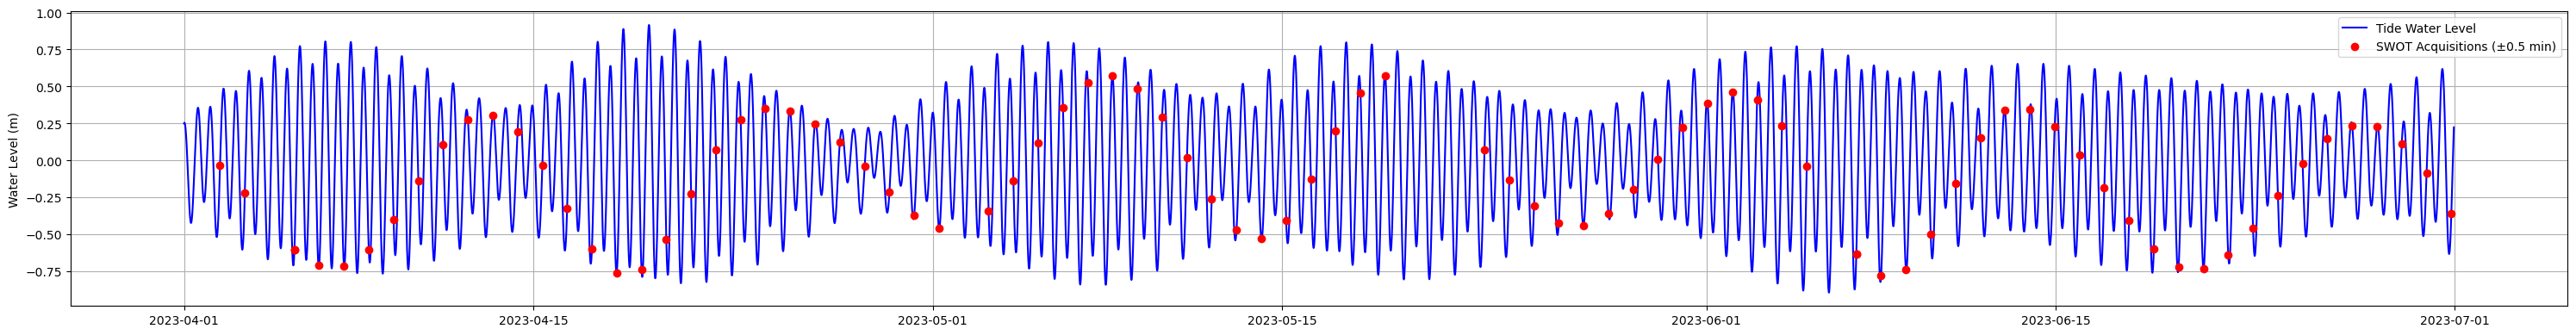

In [13]:
# Plotting the SWOT acquisitions in relation to tides

def main():
    # Step 1: Load water level data and parse datetime
    df = pd.read_csv("/Users/skica/Desktop/2025_Summer_Research/SWOTRaster Products Komo Estuary April 10 - 17, 220250610025002/test2_cal_val.csv") #WL data from TPXO tide
    df['datetime'] = pd.to_datetime(df['datetime'])  # auto-infers format
    #print(df)
    df.set_index('datetime', inplace=True)

    # swot_df = lr_data #pd.read_csv("/Users/skica/Desktop/2025_Summer_Research/SWOTRaster Products Komo Estuary April 10 - 17, 220250610025002/test2_cal_val.csv") #WL data from TPXO tide
    # swot_df['time'] = pd.to_datetime(swot_df['time'])  # auto-infers format
    # #print(df)
    # df.set_index('time', inplace=True)

    #Step 2: Extract SWOT acquisition times from filenames
    swot_dir = "/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/SWOTLR fixed20250702100716" #path to LR data files
    swot_files = sorted(glob.glob(os.path.join(swot_dir, "*.geojson")))

    swot_times = []
    for f in swot_files:
        swotfile = gpd.read_file(os.path.join(workspace, f))
        basename = os.path.basename(f)
        try:
            # Assumes the time column part is like '2023-06-18 22:25:25.896'
             if 'time' not in swotfile.columns:
                raise ValueError("Missing 'time' column")

             time_str = swotfile['time'].iloc[0]
             dt = pd.to_datetime(time_str)
             swot_times.append(dt)
            
        except Exception as e:
            print(f"Skipping {basename}: {e}")

    # Step 3: Match SWOT times to water level data within ±0.5 minutes
    matched_times = []
    matched_wse = []
    matched_files = []

    for swot_time, swot_file in zip(swot_times, swot_files):
        time_diffs = np.abs((df.index - swot_time).total_seconds())
        if (time_diffs <= 30).any():
            closest_idx = time_diffs.argmin()
            matched_times.append(df.index[closest_idx])
            matched_wse.append(df.iloc[closest_idx]['wl'])  # Ensure 'wl' exists
            matched_files.append(os.path.basename(swot_file))
            #swotFileName = os.path.basename(swotShapefile)[:62]
        else:
            print(f"No match within ±30 seconds for SWOT pass at {swot_time}")
    #print("\nMatched SWOT Acquisition Times and Water Levels:")
    #for time, wse in zip(matched_times, matched_wse):
    #    print(f"{time} -> {wse:.3f} m")
    # Optional: Save matched data
    output_df = pd.DataFrame({
        "matched_time": matched_times,
        "tpxo_wse": matched_wse,
        "swot_file": matched_files
    })
    output_df.to_csv("/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/test_tpxo_matched.csv", index=False)


    # Step 4: Plot time series with matched SWOT points
    plt.figure(figsize=(30, 4))
    plt.plot(df.index, df['wl'], color='blue', label='Tide Water Level')
    plt.scatter(matched_times, matched_wse, color='red', label='SWOT Acquisitions (±0.5 min)', zorder=5)

    plt.ylabel("Water Level (m)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

In [14]:
swot_wl = lr_data
tpxo_wl = pd.read_csv('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/test_tpxo_matched.csv')

In [15]:
swot_wl

,swotFileName,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time
0,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000
1,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000
2,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000
3,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000
4,SWOT_L2_LR_SSH_Expert_571_016_20230703T193942_...,-0.459032,12.739432,12.9301,11.7560,0.5244,2023-07-03 20:05:07.253000
...,...,...,...,...,...,...,...
92,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000
93,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000
94,SWOT_L2_LR_SSH_Expert_576_016_20230708T185252_...,0.727268,12.739432,12.9301,12.9246,0.5421,2023-07-08 19:18:16.878000
95,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000


In [16]:
tpxo_wl

,matched_time,tpxo_wse,swot_file
0,2023-04-02 10:36:04,-0.034589,SWOT_L2_LR_SSH_Expert_478_016_20230402T101101_...
1,2023-04-03 10:26:25,-0.223312,SWOT_L2_LR_SSH_Expert_479_016_20230403T100139_...
2,2023-04-05 10:08:08,-0.608045,SWOT_L2_LR_SSH_Expert_481_016_20230405T094254_...
3,2023-04-05 10:08:08,-0.608045,SWOT_L2_LR_SSH_Expert_481_016_20230405T094254_...
4,2023-04-06 09:58:29,-0.711898,SWOT_L2_LR_SSH_Expert_482_016_20230406T093332_...
...,...,...,...
82,2023-06-26 21:10:39,0.234697,SWOT_L2_LR_SSH_Expert_564_016_20230626T204517_...
83,2023-06-27 21:01:00,0.226089,SWOT_L2_LR_SSH_Expert_565_016_20230627T203555_...
84,2023-06-28 20:51:21,0.113095,SWOT_L2_LR_SSH_Expert_566_016_20230628T202633_...
85,2023-06-29 20:42:43,-0.089470,SWOT_L2_LR_SSH_Expert_567_016_20230629T201710_...


In [17]:
data_merged = pd.merge(swot_wl, tpxo_wl, left_on="swotFileName", right_on="swot_file", how="left")

In [18]:
data_merged

,swotFileName,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,matched_time,tpxo_wse,swot_file
0,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,2023-06-18 22:25:48,-0.598252,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...
1,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,2023-05-29 01:42:20,-0.199670,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...
2,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,2023-05-28 01:51:59,-0.359914,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...
3,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,2023-06-15 22:53:44,0.034614,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...
4,SWOT_L2_LR_SSH_Expert_571_016_20230703T193942_...,-0.459032,12.739432,12.9301,11.7560,0.5244,2023-07-03 20:05:07.253000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
92,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,2023-06-23 21:38:35,-0.235835,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...
93,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,2023-05-13 04:11:39,-0.471607,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...
94,SWOT_L2_LR_SSH_Expert_576_016_20230708T185252_...,0.727268,12.739432,12.9301,12.9246,0.5421,2023-07-08 19:18:16.878000,NaN,NaN,NaN
95,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,2023-06-14 23:03:23,0.227949,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...


In [19]:
data_merged.to_csv('/Users/skica/Desktop/2025_Summer_Research/work_folder/SWOT_TPXO/test_1.csv', index=False)

In [20]:
data_merged = data_merged.dropna(subset=['tpxo_wse'])


In [21]:
data_merged

,swotFileName,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,matched_time,tpxo_wse,swot_file
0,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,2023-06-18 22:25:48,-0.598252,SWOT_L2_LR_SSH_Expert_556_016_20230618T220013_...
1,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,2023-05-29 01:42:20,-0.199670,SWOT_L2_LR_SSH_Expert_535_016_20230529T011659_...
2,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,2023-05-28 01:51:59,-0.359914,SWOT_L2_LR_SSH_Expert_534_016_20230528T014434_...
3,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,2023-06-15 22:53:44,0.034614,SWOT_L2_LR_SSH_Expert_553_016_20230615T222819_...
6,SWOT_L2_LR_SSH_Expert_529_016_20230523T021312_...,0.413968,12.739432,12.9301,14.0627,-0.9093,2023-05-23 02:38:36.674000,2023-05-23 02:38:12,0.071496,SWOT_L2_LR_SSH_Expert_529_016_20230523T021312_...
...,...,...,...,...,...,...,...,...,...,...
91,SWOT_L2_LR_SSH_Expert_502_016_20230426T062612_...,0.633068,12.739432,12.9301,14.9638,-1.5913,2023-04-26 06:51:36.540000,2023-04-26 06:51:36,0.248259,SWOT_L2_LR_SSH_Expert_502_016_20230426T062612_...
92,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,2023-06-23 21:38:35,-0.235835,SWOT_L2_LR_SSH_Expert_561_016_20230623T211323_...
93,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,2023-05-13 04:11:39,-0.471607,SWOT_L2_LR_SSH_Expert_519_016_20230513T034654_...
95,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,2023-06-14 23:03:23,0.227949,SWOT_L2_LR_SSH_Expert_552_016_20230614T223742_...


In [22]:
data_merged = data_merged.drop(columns=["swotFileName", "swot_file"])

In [23]:
data_merged

,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,matched_time,tpxo_wse
0,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,2023-06-18 22:25:48,-0.598252
1,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,2023-05-29 01:42:20,-0.199670
2,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,2023-05-28 01:51:59,-0.359914
3,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,2023-06-15 22:53:44,0.034614
6,0.413968,12.739432,12.9301,14.0627,-0.9093,2023-05-23 02:38:36.674000,2023-05-23 02:38:12,0.071496
...,...,...,...,...,...,...,...,...
91,0.633068,12.739432,12.9301,14.9638,-1.5913,2023-04-26 06:51:36.540000,2023-04-26 06:51:36,0.248259
92,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,2023-06-23 21:38:35,-0.235835
93,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,2023-05-13 04:11:39,-0.471607
95,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,2023-06-14 23:03:23,0.227949


In [24]:
data_merged['swot_wse1'] = (data_merged['swot_wse_o'] + data_merged['geoid_meantide']) - data_merged['geoid']

In [25]:
data_merged

,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,matched_time,tpxo_wse,swot_wse1
0,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,2023-06-18 22:25:48,-0.598252,-0.222264
1,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,2023-05-29 01:42:20,-0.199670,0.293536
2,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,2023-05-28 01:51:59,-0.359914,0.169836
3,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,2023-06-15 22:53:44,0.034614,0.424736
6,0.413968,12.739432,12.9301,14.0627,-0.9093,2023-05-23 02:38:36.674000,2023-05-23 02:38:12,0.071496,0.604636
...,...,...,...,...,...,...,...,...,...
91,0.633068,12.739432,12.9301,14.9638,-1.5913,2023-04-26 06:51:36.540000,2023-04-26 06:51:36,0.248259,0.823736
92,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,2023-06-23 21:38:35,-0.235835,0.403236
93,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,2023-05-13 04:11:39,-0.471607,0.134136
95,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,2023-06-14 23:03:23,0.227949,0.545836


In [26]:
data_merged['swot_wse2'] = (data_merged['ssh2'] + data_merged['xover']) - data_merged['geoid']

In [27]:
data_merged

,swot_wse_o,geoid,geoid_meantide,ssh2,xover,time,matched_time,tpxo_wse,swot_wse1,swot_wse2
0,-0.412932,12.739432,12.9301,12.9141,-0.5876,2023-06-18 22:25:37.992000,2023-06-18 22:25:48,-0.598252,-0.222264,-0.412932
1,0.102868,12.739432,12.9301,13.2401,-0.3978,2023-05-29 01:42:23.917000,2023-05-29 01:42:20,-0.199670,0.293536,0.102868
2,-0.020832,12.739432,12.9301,13.2179,-0.4993,2023-05-28 01:51:46.114000,2023-05-28 01:51:59,-0.359914,0.169836,-0.020832
3,0.234068,12.739432,12.9301,14.5606,-1.5871,2023-06-15 22:53:44.009000,2023-06-15 22:53:44,0.034614,0.424736,0.234068
6,0.413968,12.739432,12.9301,14.0627,-0.9093,2023-05-23 02:38:36.674000,2023-05-23 02:38:12,0.071496,0.604636,0.413968
...,...,...,...,...,...,...,...,...,...,...
91,0.633068,12.739432,12.9301,14.9638,-1.5913,2023-04-26 06:51:36.540000,2023-04-26 06:51:36,0.248259,0.823736,0.633068
92,0.212568,12.739432,12.9301,13.0157,-0.0637,2023-06-23 21:38:48.168000,2023-06-23 21:38:35,-0.235835,0.403236,0.212568
93,-0.056532,12.739432,12.9301,14.7441,-2.0612,2023-05-13 04:12:18.519000,2023-05-13 04:11:39,-0.471607,0.134136,-0.056532
95,0.355168,12.739432,12.9301,10.6857,2.4089,2023-06-14 23:03:06.386000,2023-06-14 23:03:23,0.227949,0.545836,0.355168


In [28]:
## Computing the Errors and bias of SWOT and TPXO
tpxo_wse = data_merged['tpxo_wse']
swot_wse = data_merged['swot_wse_o']

diff = tpxo_wse - swot_wse
mae = mean_absolute_error(tpxo_wse, swot_wse)
mb = ((swot_wse - tpxo_wse).sum()) / len(swot_wse)
rho2, pval2 = pearsonr(tpxo_wse, swot_wse)
rmse = np.sqrt((diff**2).mean())

print(f'MAE (m): {mae:.3f}')
print(f'Bias (m): {mb:.3f}')
print(f'Pearson r: {rho2:.3f}', f'p-val: {pval2:.3f}')
print(f'RMSE (m): {rmse:.3f}')
print("Count: ",len(tpxo_wse))

MAE (m): 0.348
Bias (m): 0.338
Pearson r: 0.881 p-val: 0.000
RMSE (m): 0.384
Count:  87


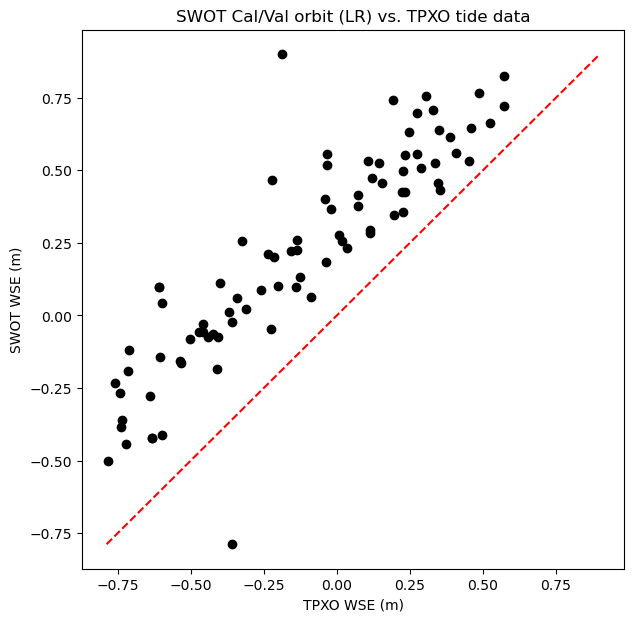

In [29]:
fig, ax = plt.subplots(figsize=(7, 7))
plt.scatter(tpxo_wse,swot_wse, color='black')
min_val = min(min(swot_wse), min(tpxo_wse))
max_val = max(max(swot_wse), max(tpxo_wse))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='1:1 line')
plt.xlabel("TPXO WSE (m)")
plt.ylabel('SWOT WSE (m)')
plt.title("SWOT Cal/Val orbit (LR) vs. TPXO tide data")
plt.savefig("/Users/skica/Desktop/2025_Summer_Research/FINAL_PRESENTATION_FIGURES/tpxo_swot_scatter3.pdf")